# Stereo-seq mouse brain — segmentation-free cell-type map (cellman.spatial)

End-to-end **count-platform** pipeline for a Stereo-seq (STOmics) whole mouse brain,
using the new `cellman.spatial` **count (blur) backend**.

**Pipeline**
`load_stereoseq → select_gene_panel → compute_vf (blur) → downsample_vector (lookup) →
cluster_vectors → (agentic annotation) → merge → map_celltypes → filter → plot`

**Why this differs from the transcript path (Xenium/MERFISH)**
Stereo-seq gives a **bin × gene count matrix**, not molecule-resolved transcripts. So the
KDE-equivalent vector field is built by **rasterizing bin counts and GPU-blurring** them
(`analysis.compute_vf`), persisting only `vf_normalized`. Voxels are then *looked up* in
that field by `downsample_vector(grid=...)` instead of KDE-at-points. The gene panel is
**HVG ∪ Cell-Ontology markers**; the KG URL is passed explicitly (no hardcoded IP).

## Step 0 — Configuration

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT     = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
DATA     = f"{ROOT}/cellman_paper/data/stereoseq/mosta"
GEM      = f"{DATA}/Mouse_brain_Adult_GEM_bin1.tsv.gz"   # bin1 GEM (geneID/x/y/MIDCounts)
SSDNA    = f"{DATA}/Mouse_brain_Adult.tif"               # ssDNA staining image
STORE    = f"{ROOT}/CeLLMan_notebooks/ST_bench/stereoseq_brain"
SDATA    = f"{STORE}/stereoseq_brain.sdata.zarr"     # unified input+output SpatialData
SCRIPTS  = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

SPECIES, ORGAN = "mouse", "whole_brain"     # Cell-Ontology wing for the gene panel
ONTO_API   = "http://10.125.208.41:8088"    # KG REST server (dev); or set None → HVG-only
DEVICE     = "cuda:1"                        # NOTE: CUDA 0 = RTX 4090 (opposite of nvidia-smi)
NCORES     = 30

# vector-field geometry
BIN_UM       = 0.5     # rasterization grid (µm); Stereo-seq native DNB = 0.5 µm
BANDWIDTH_UM = 8     # Gaussian blur bandwidth (µm)
SIGMA_BIN    = BANDWIDTH_UM / BIN_UM        # σ in bin units
SAMPLING_DIST = 1.0     # sampling distance (µm)
HVG_BIN_UM   = 8.0     # coarse pseudo-bin for HVG variance estimate
HVG_N        = 5000

Path(STORE).parent.mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.i

cellman.spatial 0.1.0


## Step 1 — Load Stereo-seq → `GridDataset`

`load_stereoseq` reads the bin1 GEM into a µm-coordinate count AnnData and resolves the
ssDNA→lattice affine (mirror-flip chosen by count-density ↔ ssDNA-intensity correlation).

In [2]:
import spatialdata as sd
if Path(SDATA).exists():
    sdata = sd.read_zarr(SDATA); print("loaded existing sdata:", SDATA)
else:
    sdata = cms.load_stereoseq(GEM, SSDNA, species=SPECIES, organ=ORGAN, bin_size=1)
    sdata.write(SDATA)   # persist unified input (tables['table'] + images['staining']); one-time
grid  = cms.GridDataset.from_sdata(sdata)   # lightweight view for HVG coarse-bin / panel
print("sdata:", dict(tables=list(sdata.tables), images=list(sdata.images)))
print("raw bins:", grid.raw.n_obs, "| genes:", grid.n_genes,
      "| origin µm:", tuple(round(v,1) for v in grid.origin),
      "| flip:", grid.meta.get("flip"))

loaded existing sdata: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain/stereoseq_brain.sdata.zarr
sdata: {'tables': ['table'], 'images': ['staining']}
raw bins: 42147676 | genes: 26177 | origin µm: (0.0, 0.0) | flip: [0 0]


In [3]:
sdata

SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain/stereoseq_brain.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (1, 26455, 26449)
└── Tables
      └── 'table': AnnData (42147676, 26177)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)

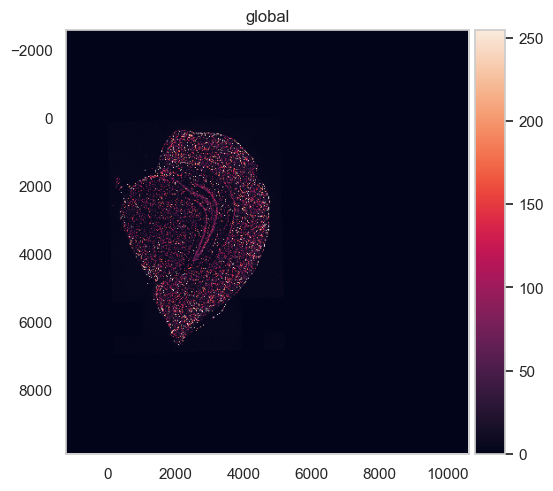

In [4]:
import spatialdata_plot

sdata.pl.render_images('staining').pl.show()

## Step 2 — Gene panel = HVG ∪ Cell-Ontology markers

HVG is estimated on a coarse `HVG_BIN_UM` aggregation (denser bins → cleaner variance);
ontology markers for `mouse/whole_brain` are unioned in. If the KG server is unreachable
this degrades to HVG-only automatically.

In [5]:
coarse = cms.aggregate_to_grid(grid.raw, bin_um=HVG_BIN_UM, origin=grid.origin)
panel, onto_markers = cms.select_gene_panel(
    coarse, SPECIES, ORGAN, hvg_n=HVG_N, server_url=ONTO_API)
print("panel genes:", len(panel), "| ontology markers in panel:", len(onto_markers))
del coarse

[panel] HVG (seurat_v3 on 100000 bins, denylist-filtered): 3220
[panel] slim-index mouse/whole_brain: n_terms=449 version=2026-07-14 → 923 marker genes
[panel] final panel: 3846 genes (HVG 3220 ∪ ontology-in-data 884)
panel genes: 3846 | ontology markers in panel: 884


## Step 3 — `compute_vf` (rasterize + GPU blur)

Aggregates the panel counts to a `BIN_UM` grid and Gaussian-blurs into `vf_normalized`
(bandwidth = `SIGMA_BIN * BIN_UM` µm). Only the normalized field is persisted.

In [4]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['coordinate_bounds', 'coordinate_offset', 'downsampled_global_xy', 'downsampled_vectors', 'downsampled_vf_norm', 'genes', 'kde_computed', 'normalized_vectors', 'original_coordinate_bounds', 'stereoseq_brain.sdata.zarr', 'vf_norm', 'vf_normalized', 'vf_params']
Loaded existing KDE results.
Loaded existing local maxima.
Loaded a precomputed normalized vector.
Loaded existing gene list.
Loaded a precomputed normalized vector field.


In [7]:
analysis.compute_vf(sdata, bin_um=BIN_UM, panel=panel,
                    sampling_distance=SAMPLING_DIST, sigma_bin=SIGMA_BIN, device=DEVICE)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=14, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
compute_vf (blur, tiled): 100%|██████████| 109/109 [23:51<00:00, 13.13s/it]

[compute_vf] blur raster (13950, 10500)@0.5µm → vf (3846, 6975, 5250)@1.0µm (stride 2, compute tile 64×512, store chunk 32×32, radius 69, bandwidth 8.0µm, fp32)


AnnData object with n_obs × n_vars = 42147676 × 3846
    obs: 'array_row', 'array_col'
    uns: 'bin_size_um', 'grid_origin_um'
    obsm: 'spatial'

## Step 4 — `downsample_vector` (count lookup)

Samples voxels from the ssDNA tissue mask and looks them up in the blur field
(`grid=` triggers the count path; no KDE). ssDNA is bright-tissue-on-dark, so
`GridDataset.he_revert=False` thresholds directly.

In [5]:
adata = analysis.downsample_vector(sdata, n_samples_per_block=5, block_um=10,
                           vf_norm_percentile=25)
adata

downsample_vector (lookup, 15828 tiles, 30w): 100%|██████████| 15828/15828 [01:36<00:00, 163.57it/s]


[downsample] otsu=71.22 mask_px=12888219 sampled=136521 kept(vf_norm>0.09039)=126486


AnnData object with n_obs × n_vars = 126486 × 3846
    obs: 'vf_norm'
    obsm: 'spatial'

/tmp/ipykernel_3551517/538303742.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color='vf_norm', spot_size=10)


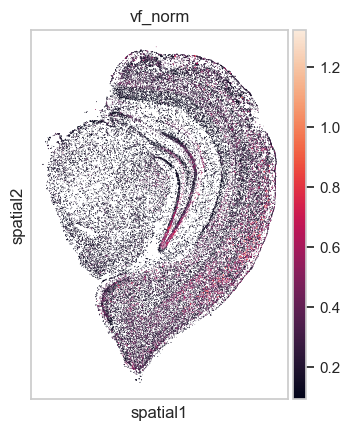

In [6]:
import scanpy as sc

sc.pl.spatial(adata, color='vf_norm', spot_size=10)

In [8]:
adata.write_h5ad(f"{STORE}/mouse_brain_cls.h5ad")

## Step 6 — Agentic annotation (external step)

Run the **annotate-mode** (or **annotate-kg-mode**) skill on `ssam_clusters.h5ad`
(mouse / whole_brain wing). It writes `annotation_out/ssam_clusters_annotated.h5ad`
with `obs['celltype_annotation']`. Continue once it exists.

/annotate-mode-v2 Annotate the h5ad below using the mouse-brain-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain/mouse_brain_cls.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain
- tissue : mouse, brain          
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- note : use 5090 GPU on device '1'

In [2]:
ROOT     = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
STORE    = f"{ROOT}/CeLLMan_notebooks/ST_bench/stereoseq_brain"

In [9]:
import scanpy as sc

anno = sc.read_h5ad(f'{STORE}/annotation_out/mouse_brain_cls_annotated.h5ad')
anno

AnnData object with n_obs × n_vars = 126486 × 3846
    obs: 'vf_norm', 'cellman_class', 'cellman_process', 'leiden', 'cellman_annotation'
    uns: 'cellman_cluster_params', 'cellman_partition'
    obsm: 'spatial'

/tmp/ipykernel_3551517/1153336930.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


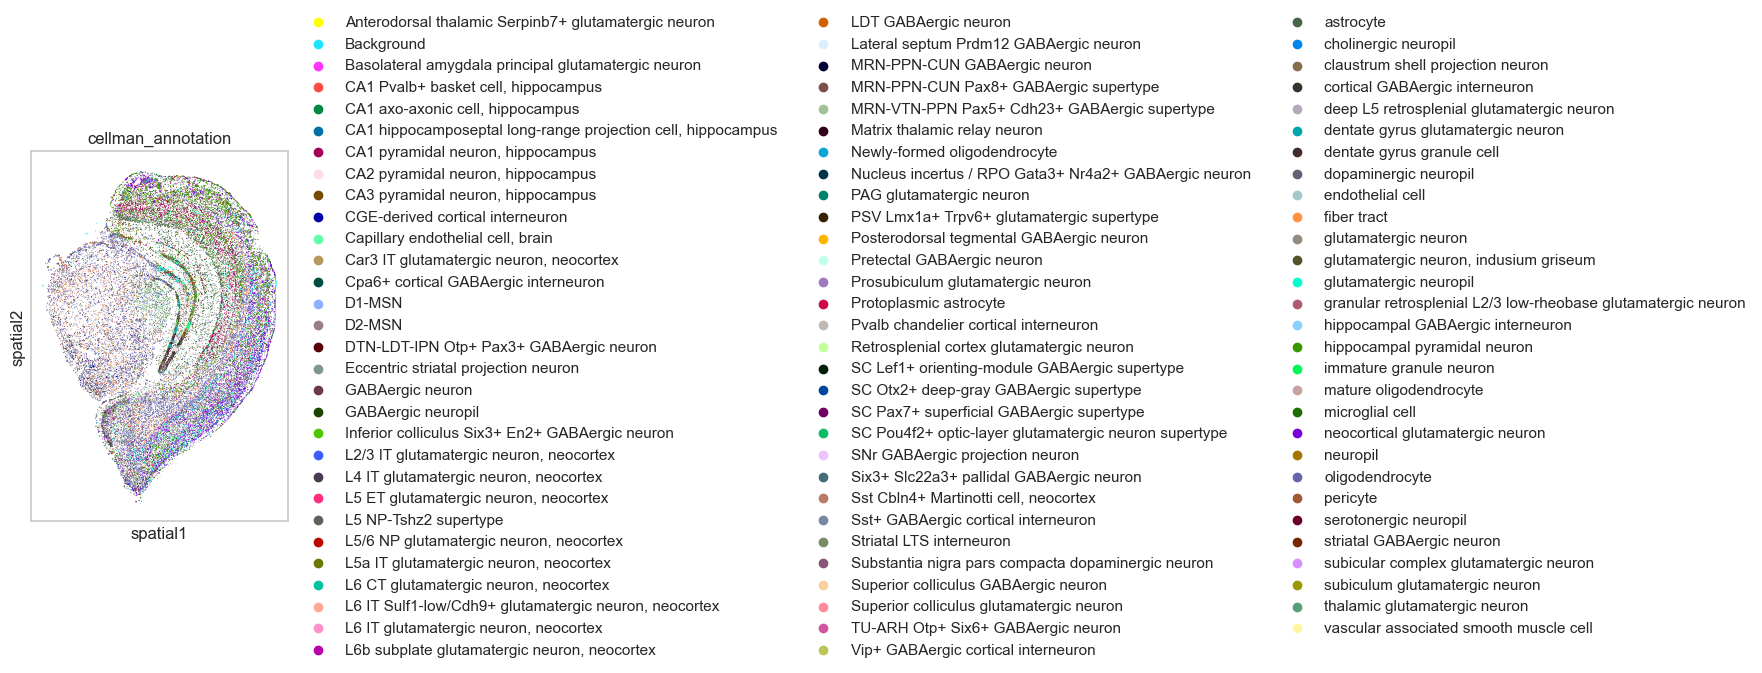

In [10]:
sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)

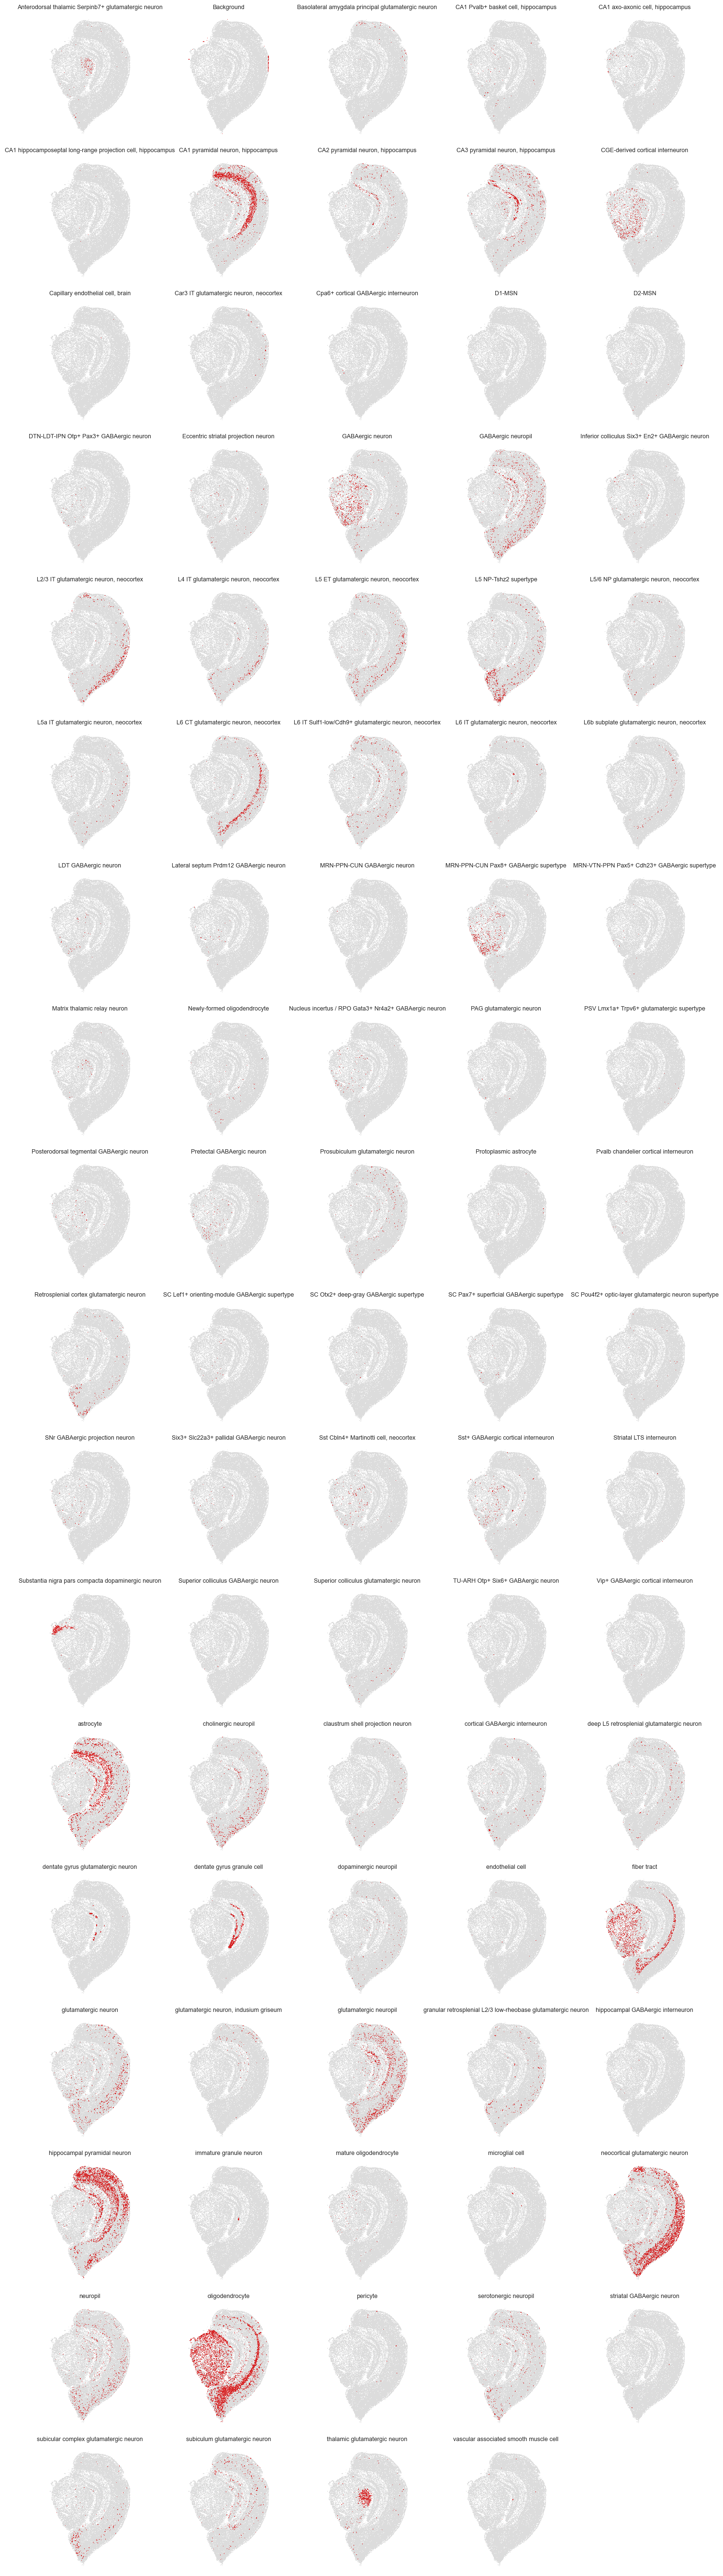

In [11]:
import math, matplotlib.pyplot as plt
COL='cellman_annotation'; PS=0.5; N_COLS=5; BG='#dcdcdc'; FG='#d62728'
xy = anno.obsm['spatial']; labels = anno.obs[COL].astype(str).to_numpy()
cats = list(anno.obs[COL].cat.categories); n=len(cats)
n_cols=min(N_COLS,n); n_rows=math.ceil(n/n_cols)
fig,axes=plt.subplots(n_rows,n_cols,figsize=(3*n_cols,3*n_rows),squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i,ct in enumerate(cats):
    a_=axes[i//n_cols,i%n_cols]; m=labels==ct
    a_.scatter(xy[~m,0],xy[~m,1],s=PS,c=BG,linewidths=0,rasterized=True)
    a_.scatter(xy[m,0], xy[m,1], s=PS,c=FG,linewidths=0,rasterized=True)
    a_.set_title(ct,fontsize=9); a_.set_aspect('equal'); a_.invert_yaxis()
fig.tight_layout(); plt.show()

## Step 7 — Merge annotated clusters → centroids

In [12]:
import subprocess, sys
subprocess.run([sys.executable, f"{SCRIPTS}/build_mapping_inputs.py",
                "--store-dir", STORE,
                "--annotate-out", f"{STORE}/annotation_out",
                "--column", "cellman_annotation",
                "--legacy"], check=True)

[build-mapping] auto-discovered annotated h5ad: mouse_brain_cls_annotated.h5ad
[build-mapping] store-dir : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain
[build-mapping] h5ad      : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain/annotation_out/mouse_brain_cls_annotated.h5ad
[build-mapping] dry-run   : False
[build-mapping] label col : cellman_annotation   (n_vectors=126486)
[build-mapping] mode: LEGACY (group by label string)

[build-mapping] 88 celltypes:
    id=  0  CA1 pyramidal neuron, hippocampus  [celltype]  (7675 vectors)
    id=  1  CA3 pyramidal neuron, hippocampus  [celltype]  (2751 vectors)
    id=  2  L2/3 IT glutamatergic neuron, neocortex  [celltype]  (1841 vectors)
    id=  3  Prosubiculum glutamatergic neuron  [celltype]  (467 vectors)
    id=  4  Retrosplenial cortex glutamatergic neuron  [celltype]  (720 vectors)
    id=  5  hippocampal pyramidal neuron  [celltype]  (15968 vector

CompletedProcess(args=['/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/bin/python', '/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan/cellman/spatial/scripts/build_mapping_inputs.py', '--store-dir', '/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain', '--annotate-out', '/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/stereoseq_brain/annotation_out', '--column', 'cellman_annotation', '--legacy'], returncode=0)

## Step 8 — `map_celltypes` over the blur field

For count data the field is already built, so `map_celltypes` reads it and maps every
voxel by `method`:
- `'corr'` — centroid Pearson (default; matches the transcript path),
- `'tsvm'` — linear/transductive SVM (higher label fidelity),
- `'knn'`  — k-NN vote.

No `sdata` and no GPU KDE — it streams `vf_normalized`.

In [13]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['centroids', 'centroids_stdev', 'cluster_labels', 'coordinate_bounds', 'coordinate_offset', 'downsampled_global_xy', 'downsampled_vectors', 'downsampled_vf_norm', 'filtered_cluster_labels', 'genes', 'kde_computed', 'normalized_vectors', 'original_coordinate_bounds', 'stereoseq_brain.sdata.zarr', 'vf_norm', 'vf_normalized', 'vf_params']


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at celltype_index.csv is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at annotation_out is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at mouse_brain_cls.h5ad is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


Loaded existing KDE results.
Loaded existing local maxima.
Loaded a precomputed normalized vector.
Loaded existing gene list.
Loaded a precomputed normalized vector field.
Loaded existing cluster labels.


In [14]:
analysis.map_celltypes(method="tsvm", gpu_device=DEVICE,
                       map_kwargs={"apply_kwargs": {"chunk_h": 64, 'tau_conf': 0}})

[fit] dropped 352 unlabeled (-1) vectors
[fit] labeled=(126134, 3846)  k=88  FULL-GENE (no PCA)  thr=0.0904
[fit] full-gene cross-entropy: 1500 iters  train-acc=0.907
[fit] abstain_q=0.15 (Unknown = most-ambiguous 15% of field)


map_celltypes_tsvm[full]: 100%|██████████| 109/109 [07:52<00:00,  4.34s/it]


[map] assigned 18492826 voxels (tau_conf=0.000)


## Step 9 — Filter + plot the cell-type map

In [15]:
analysis.filter_celltypemaps(min_p=0.9)

In [18]:
import numpy as np
np.unique(ds.cluster_labels)

array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32,
       33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49,
       50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66,
       67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83,
       84, 85, 86, 87])

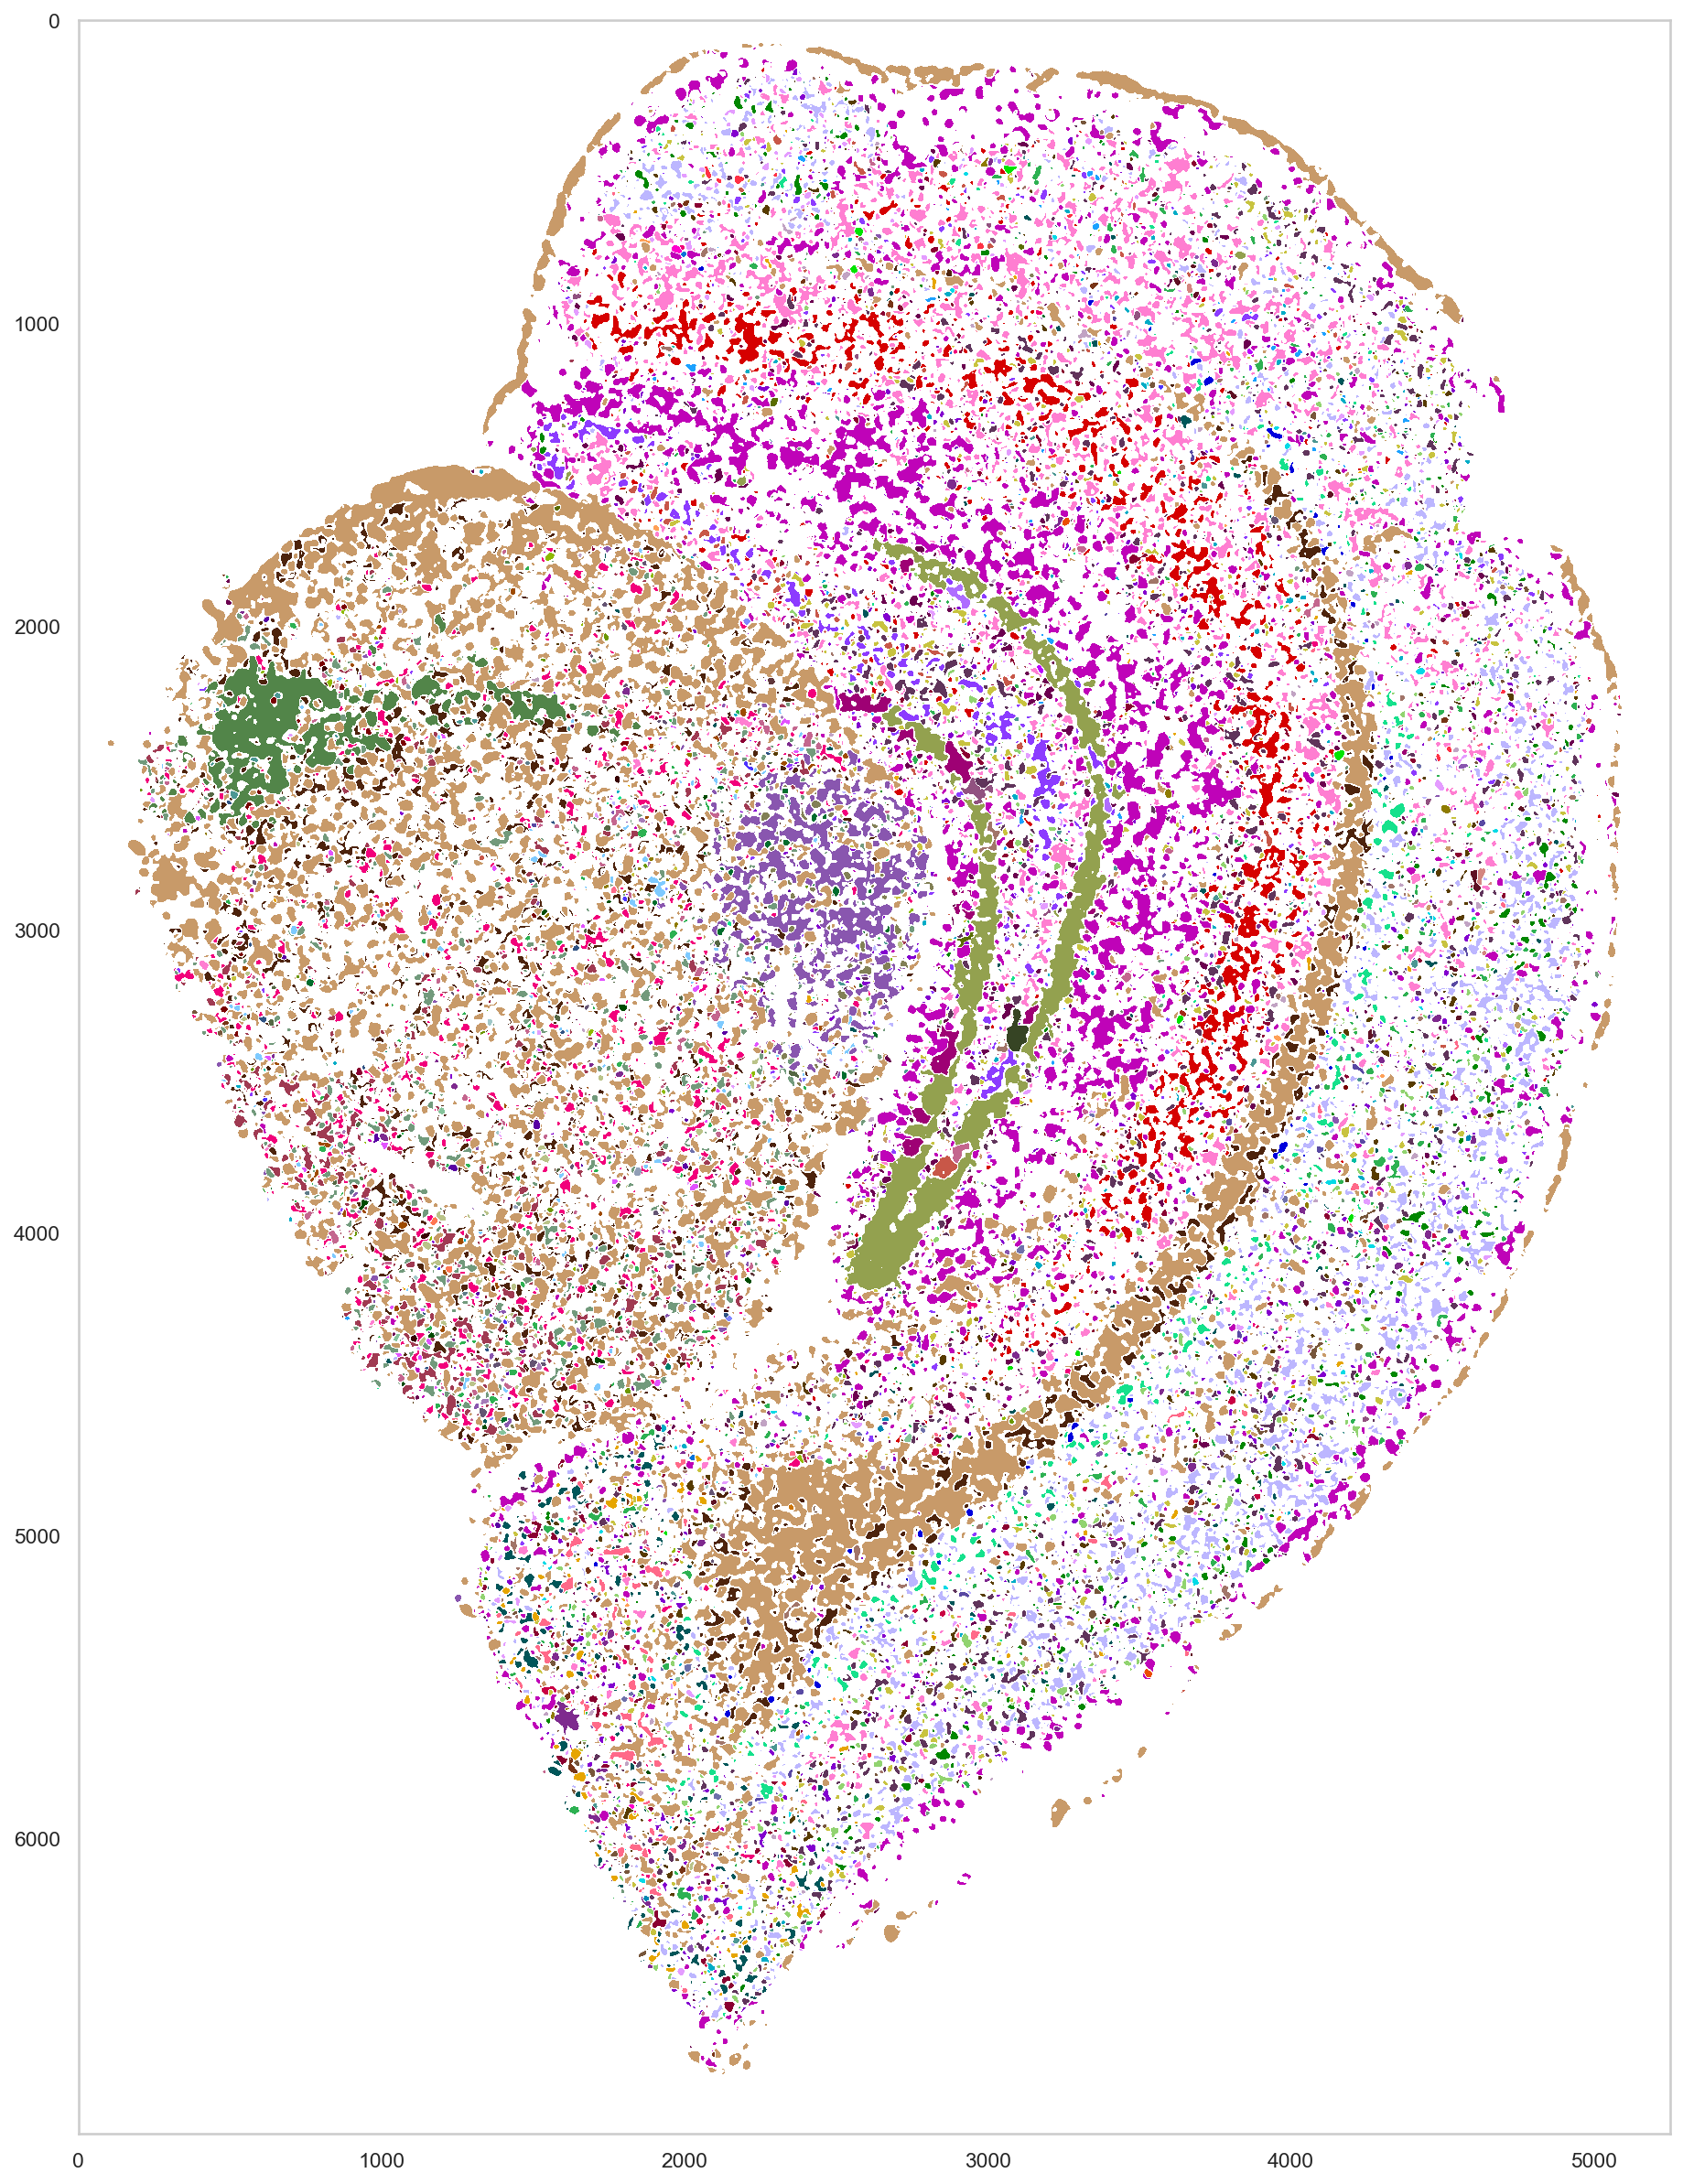

In [19]:
import colorcet as cc
COLORS = cc.glasbey_bw_minc_20_maxl_70[:88]   # 흰 배경용: 명도 ≤70, 최소채도 20

import matplotlib.pyplot as plt
plt.figure(figsize=(20, 20), dpi=150)        
ds.plot_celltypes_map(background="w", colors=COLORS,
                      show_annotation=False,
                      annotation_csv=f"{STORE}/celltype_index.csv")
plt.show()

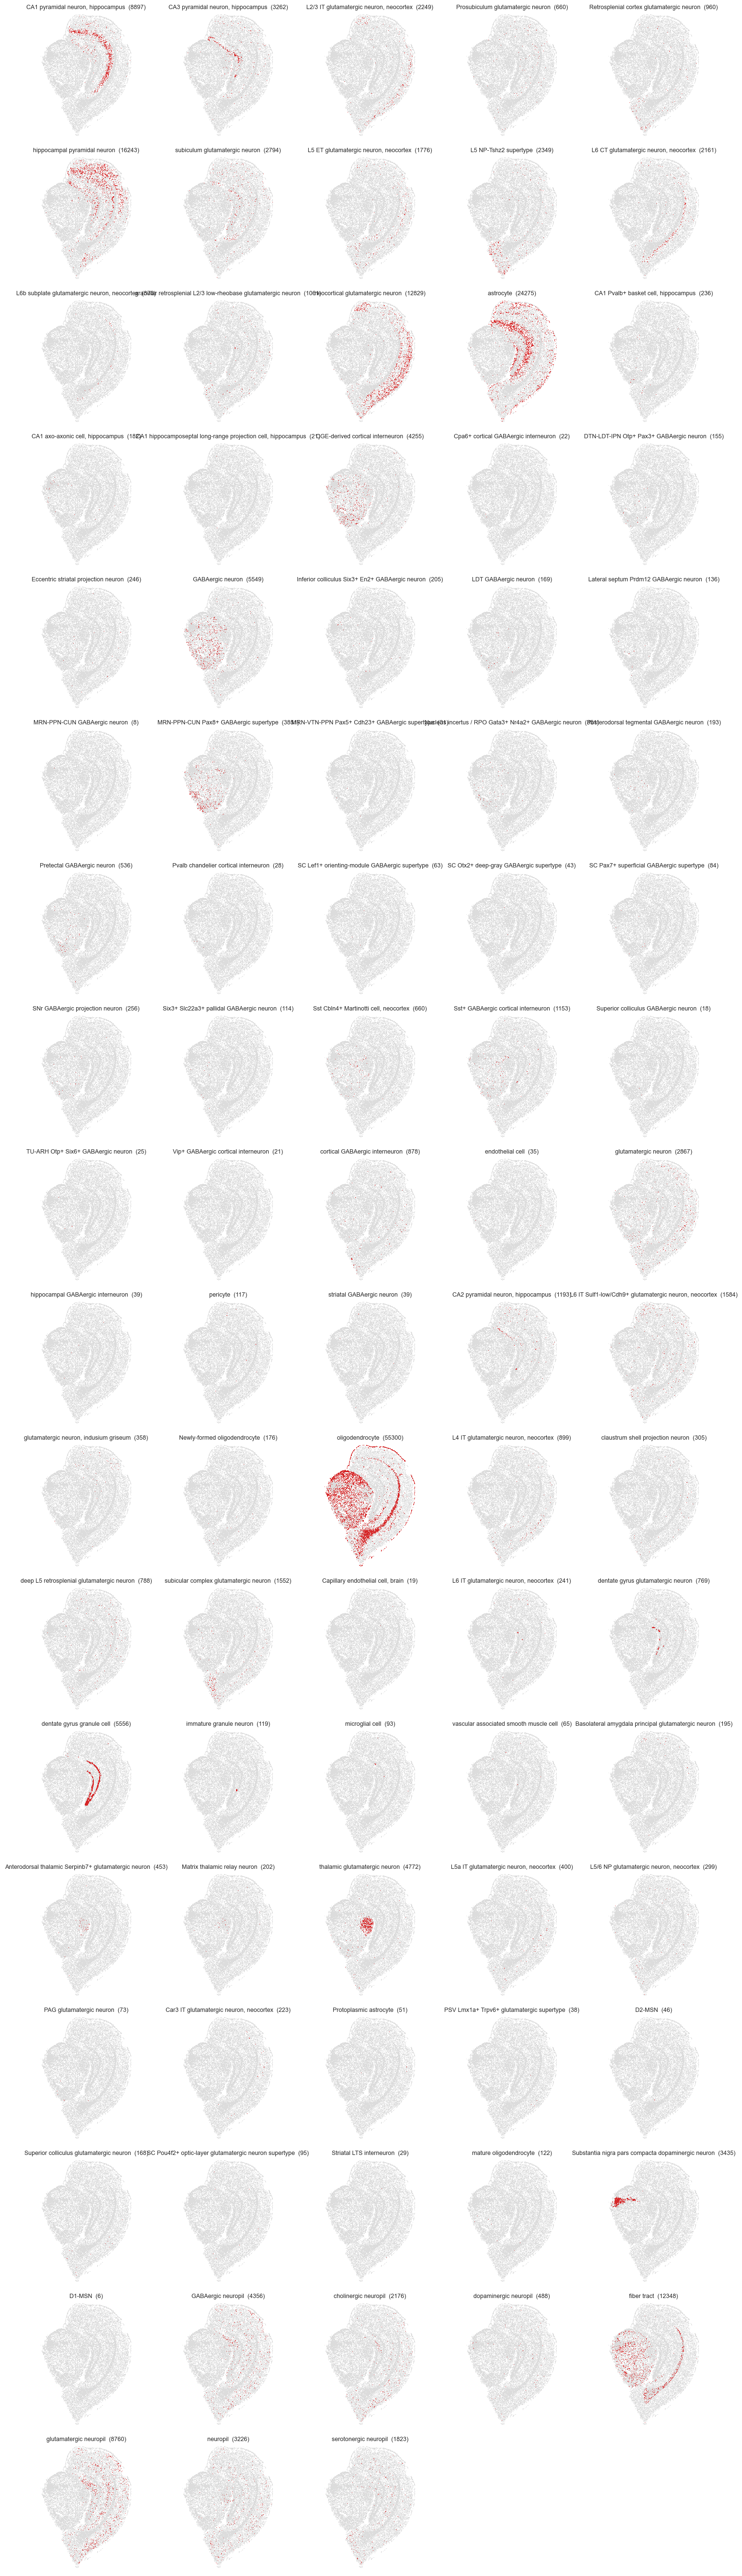

In [20]:
import math, numpy as np, zarr, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

S=8; N_COLS=5; OFF='white'; BG='#dcdcdc'; FG='#d62728'   # S: 블록 축소 배율

z   = zarr.open(STORE, mode='r')
ct  = np.asarray(z['filtered_celltype_maps'][:, :, 0])          # (X, Y), -1 = 미할당
idx = pd.read_csv(f"{STORE}/celltype_index.csv").sort_values('cluster')
cats = idx['celltype'].tolist(); ids = idx['cluster'].to_numpy()

X, Y = (ct.shape[0]//S)*S, (ct.shape[1]//S)*S
blk  = ct[:X, :Y].reshape(X//S, S, Y//S, S)                     # 블록 뷰 (복사 없음)
tissue = (blk >= 0).any(axis=(1, 3))                            # 조직 배경
# 미할당(Unknown/abstain) 영역까지 배경에 넣고 싶으면:
# vn = np.asarray(z['vf_norm'][:X,:Y]).reshape(X//S,S,Y//S,S); tissue = (vn>0).any(axis=(1,3))

n = len(cats); n_cols = min(N_COLS, n); n_rows = math.ceil(n/n_cols)
cmap = ListedColormap([OFF, BG, FG])
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows), squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i, (cid, ct_name) in enumerate(zip(ids, cats)):
    a_ = axes[i//n_cols, i%n_cols]
    m  = (blk == cid).any(axis=(1, 3))
    a_.imshow(np.where(m, 2, tissue.astype(int)).T,             # .T = (x, y) -> imshow 축
              cmap=cmap, vmin=0, vmax=2, interpolation='nearest', origin='upper')
    a_.set_title(f'{ct_name}  ({m.sum()})', fontsize=9); a_.set_aspect('equal')
fig.tight_layout(); plt.show()
